In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates

data_file = os.path.join(os.getcwd(), "..", "data", "train_cleaned.csv")
dataframe = pd.read_csv(data_file, index_col="day")
dataframe.index = pd.to_datetime(dataframe.index).tz_localize(None)

atms = [col for col in dataframe.columns if col.startswith("ATM")]

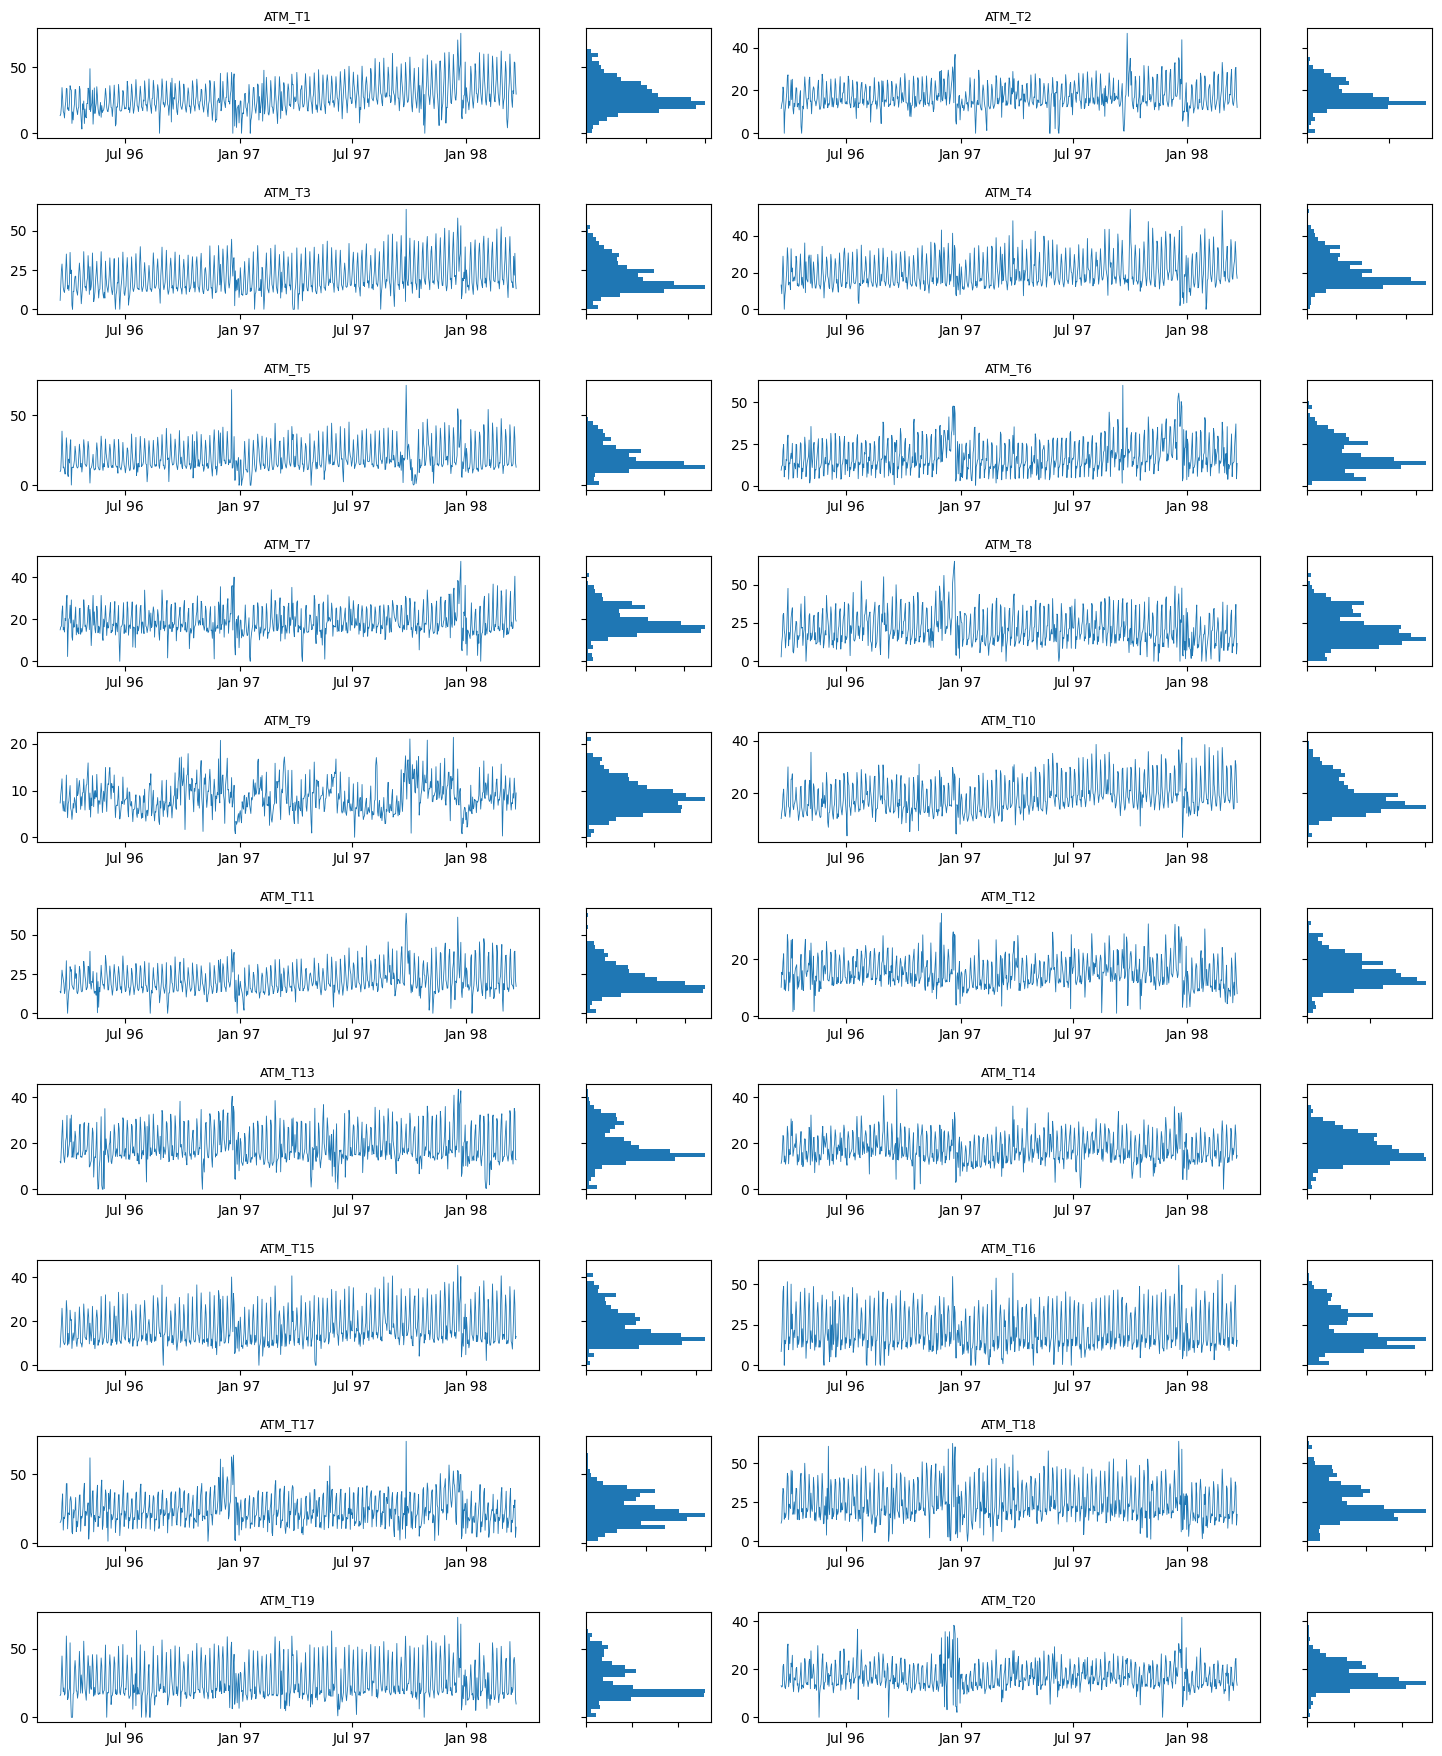

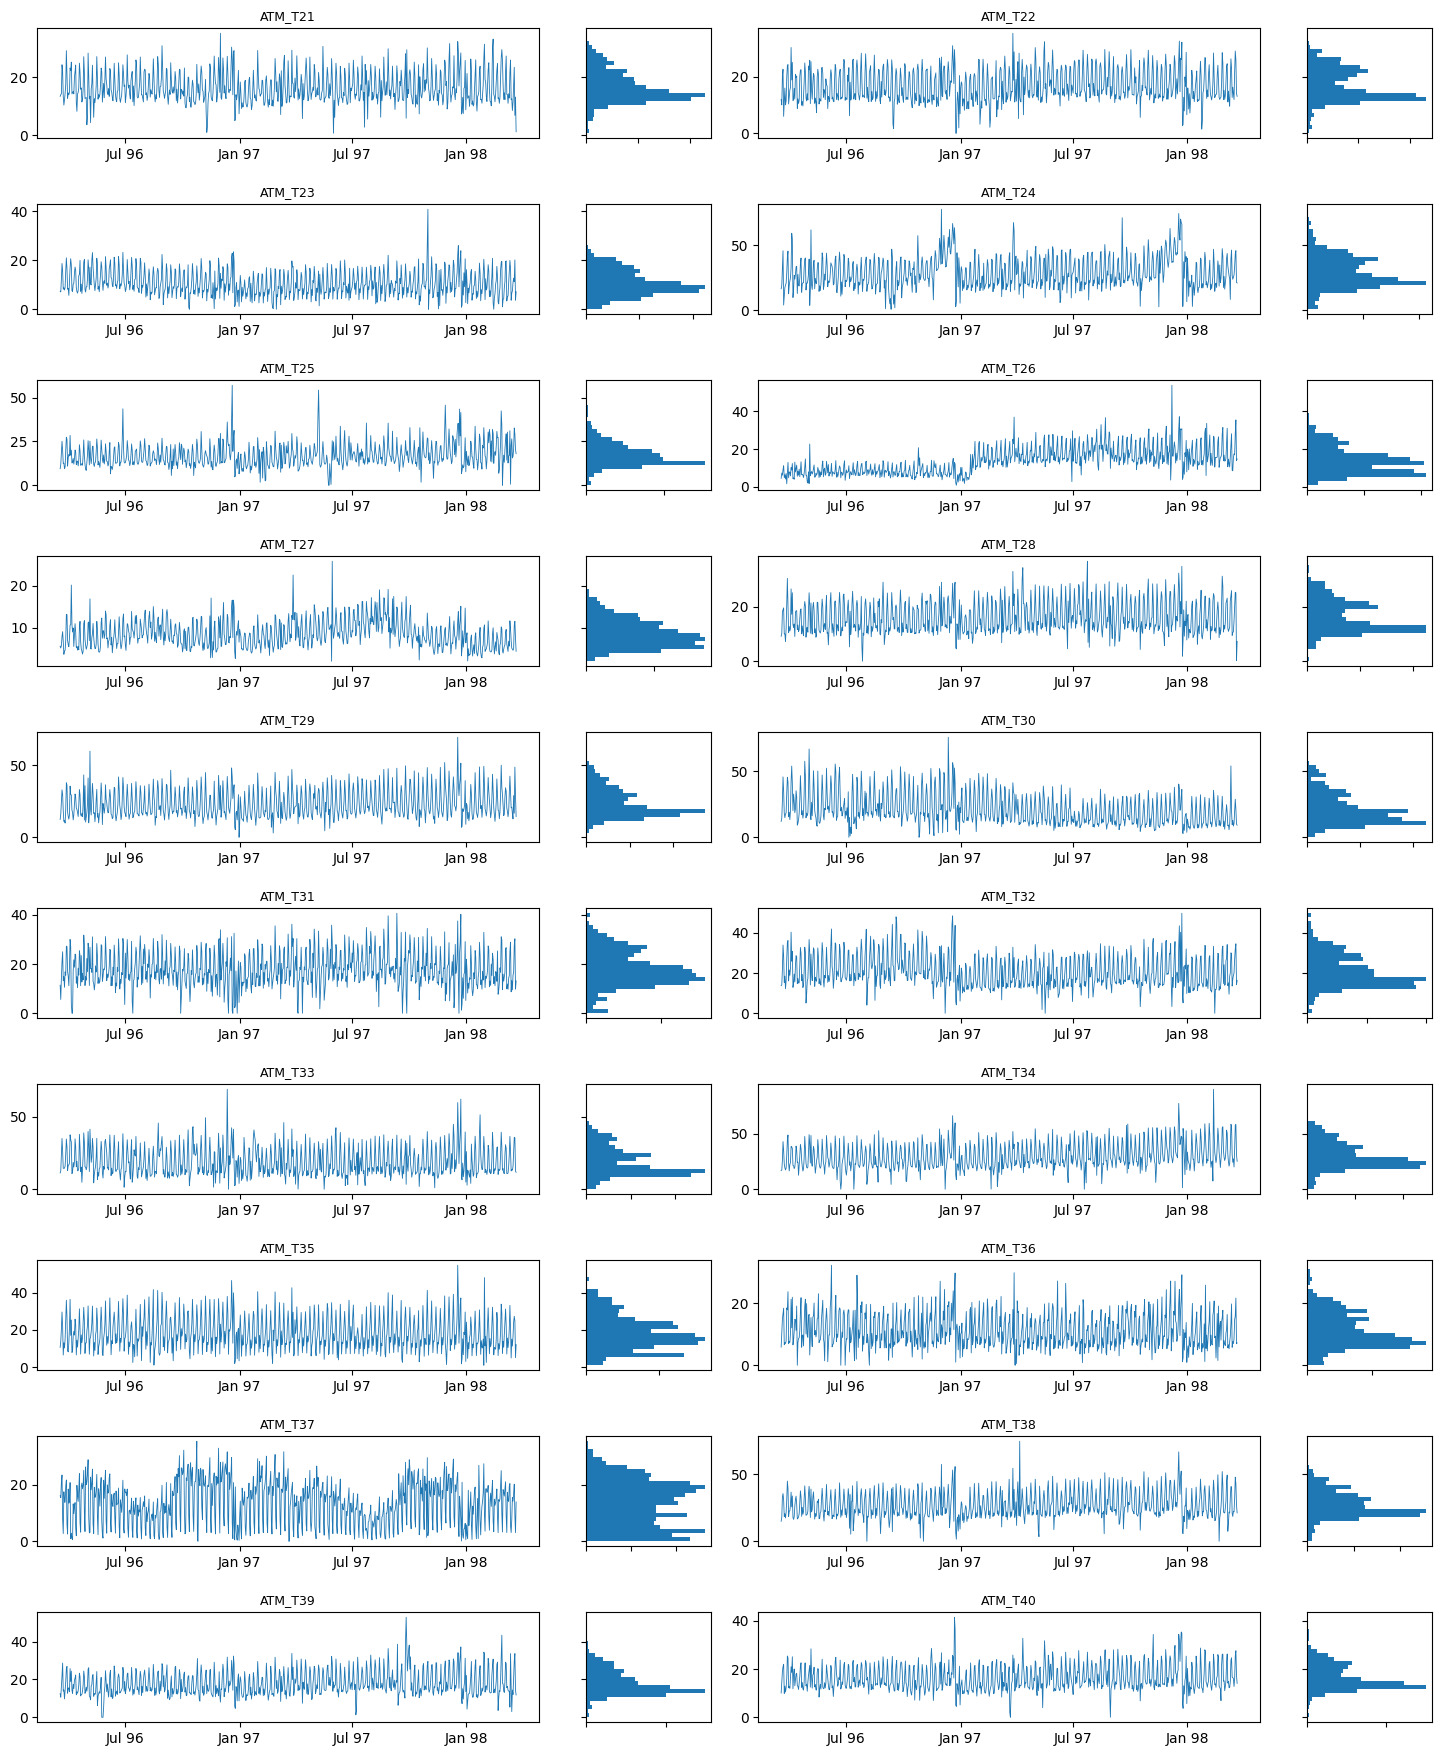

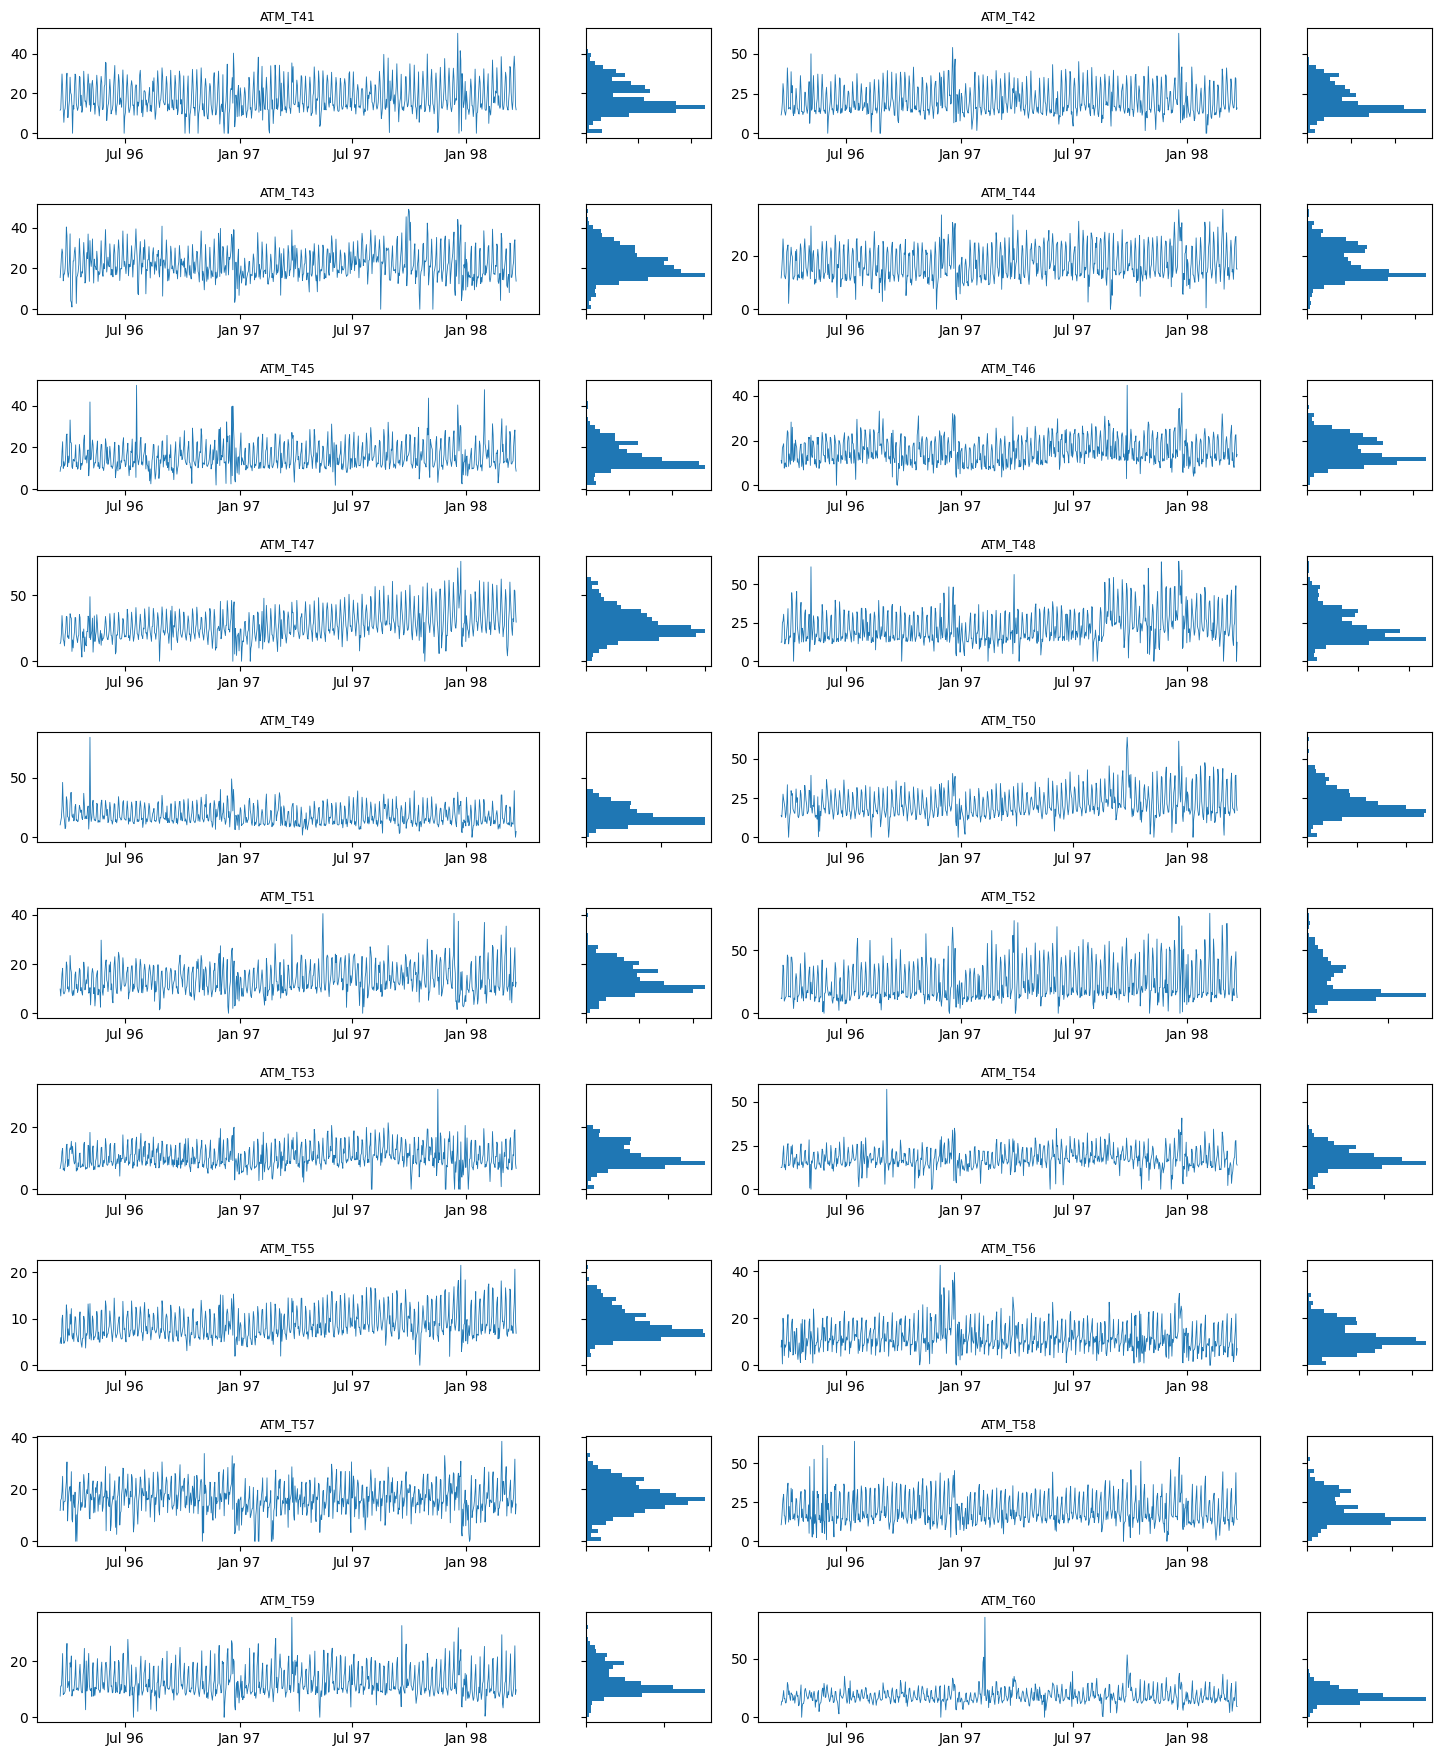

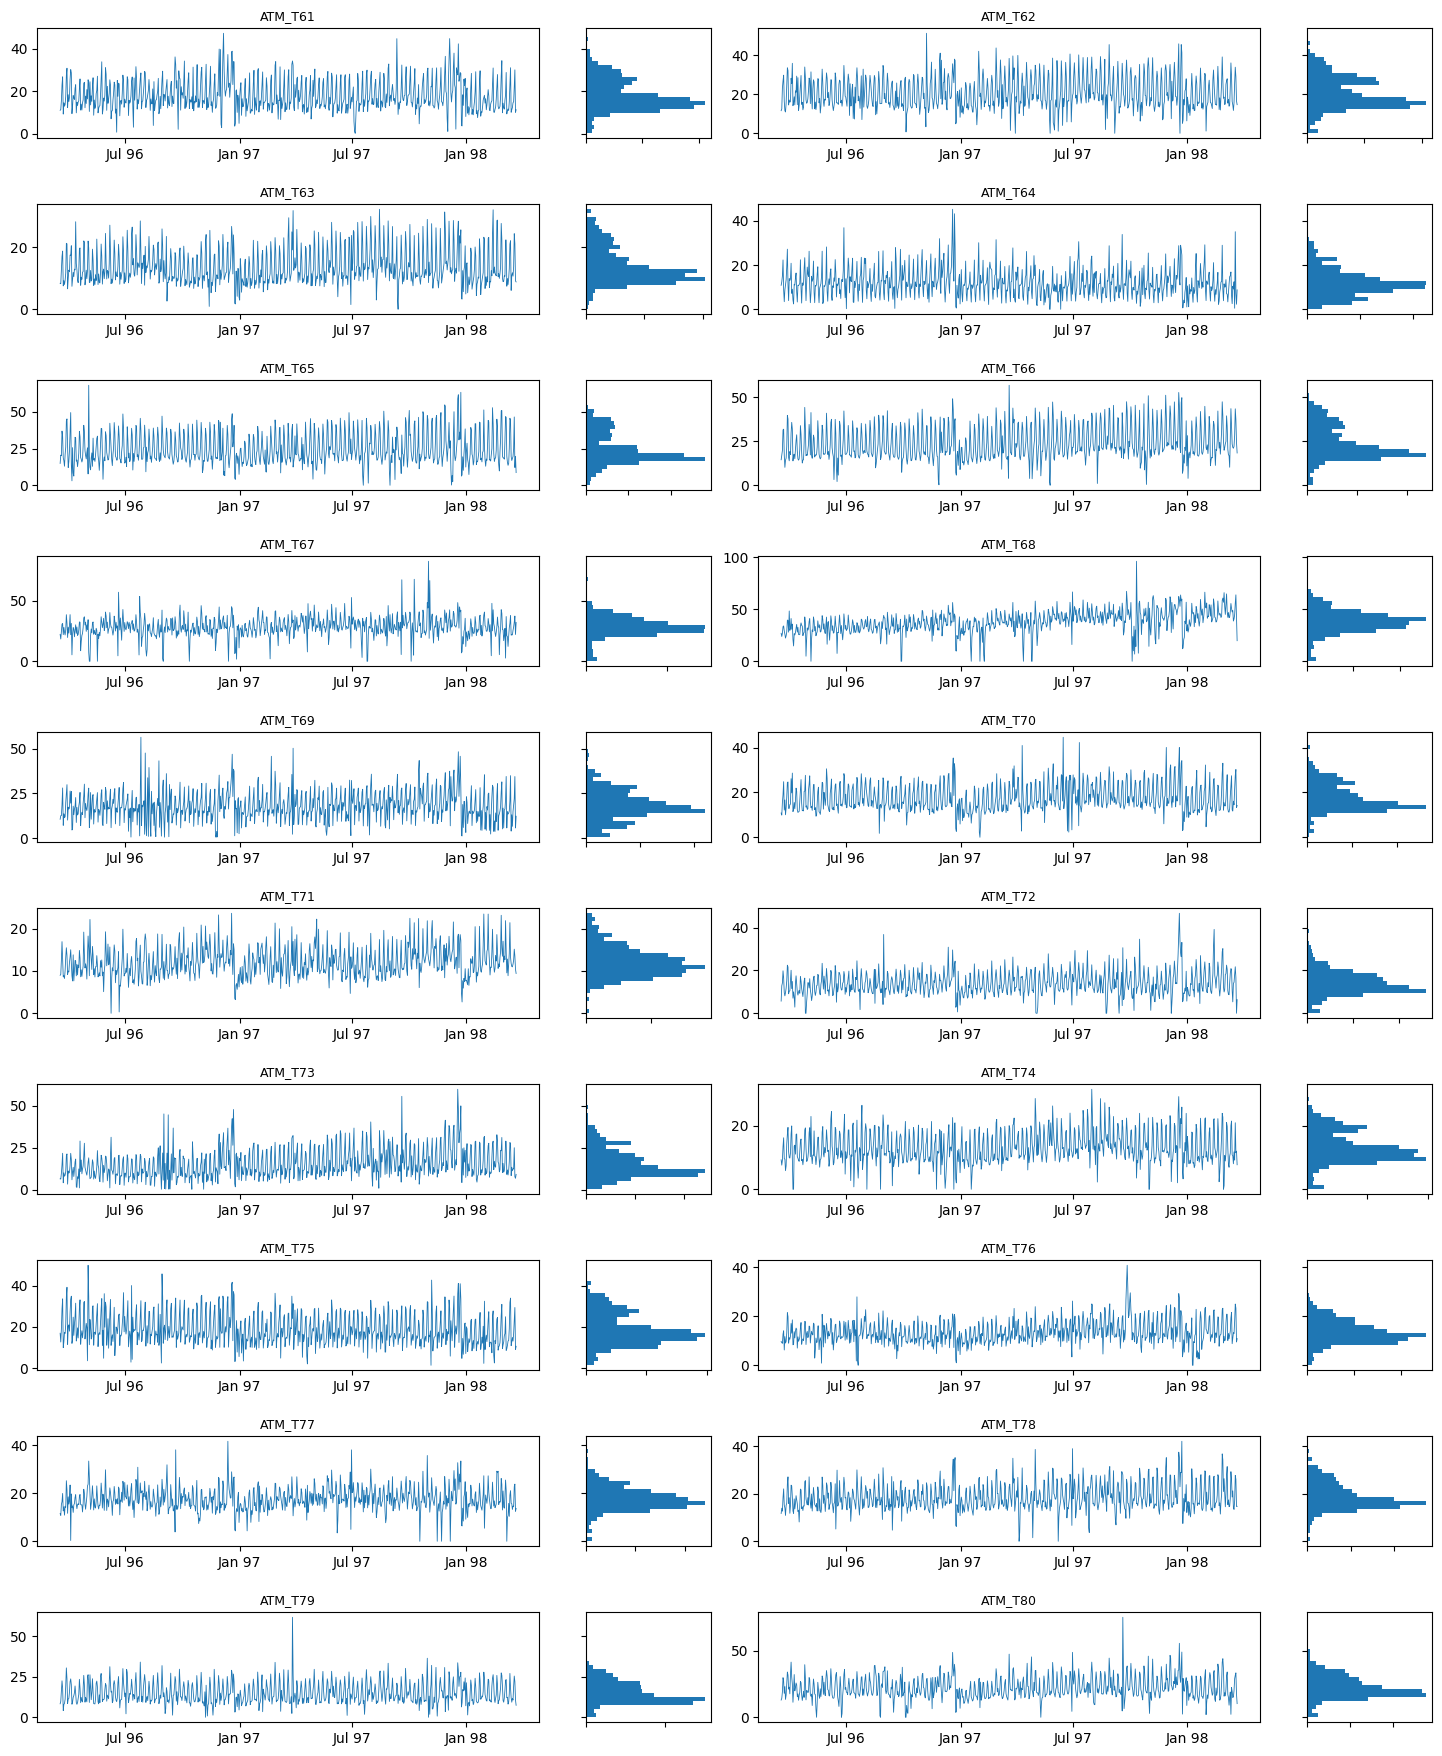

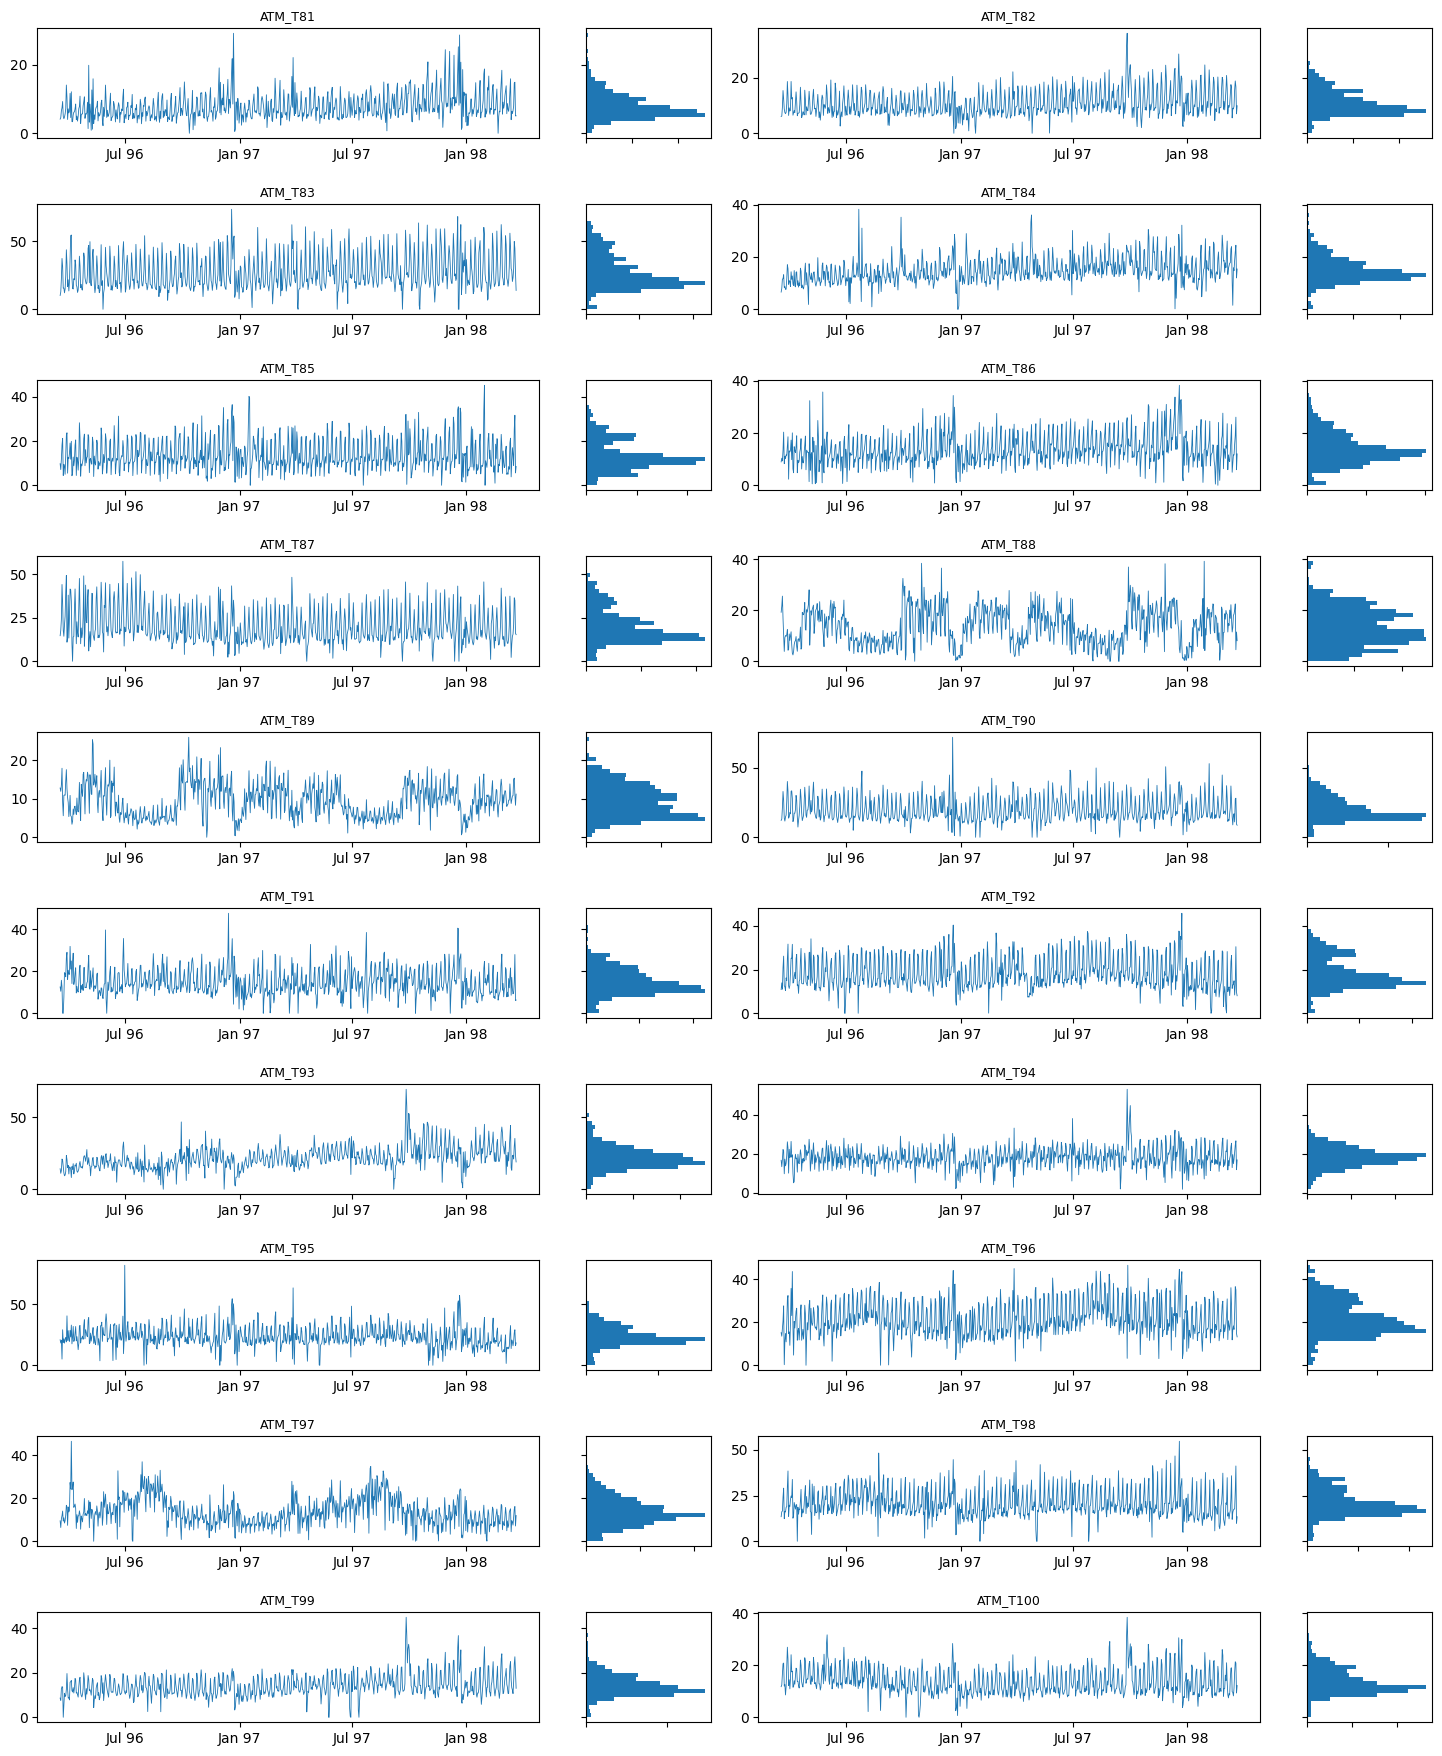

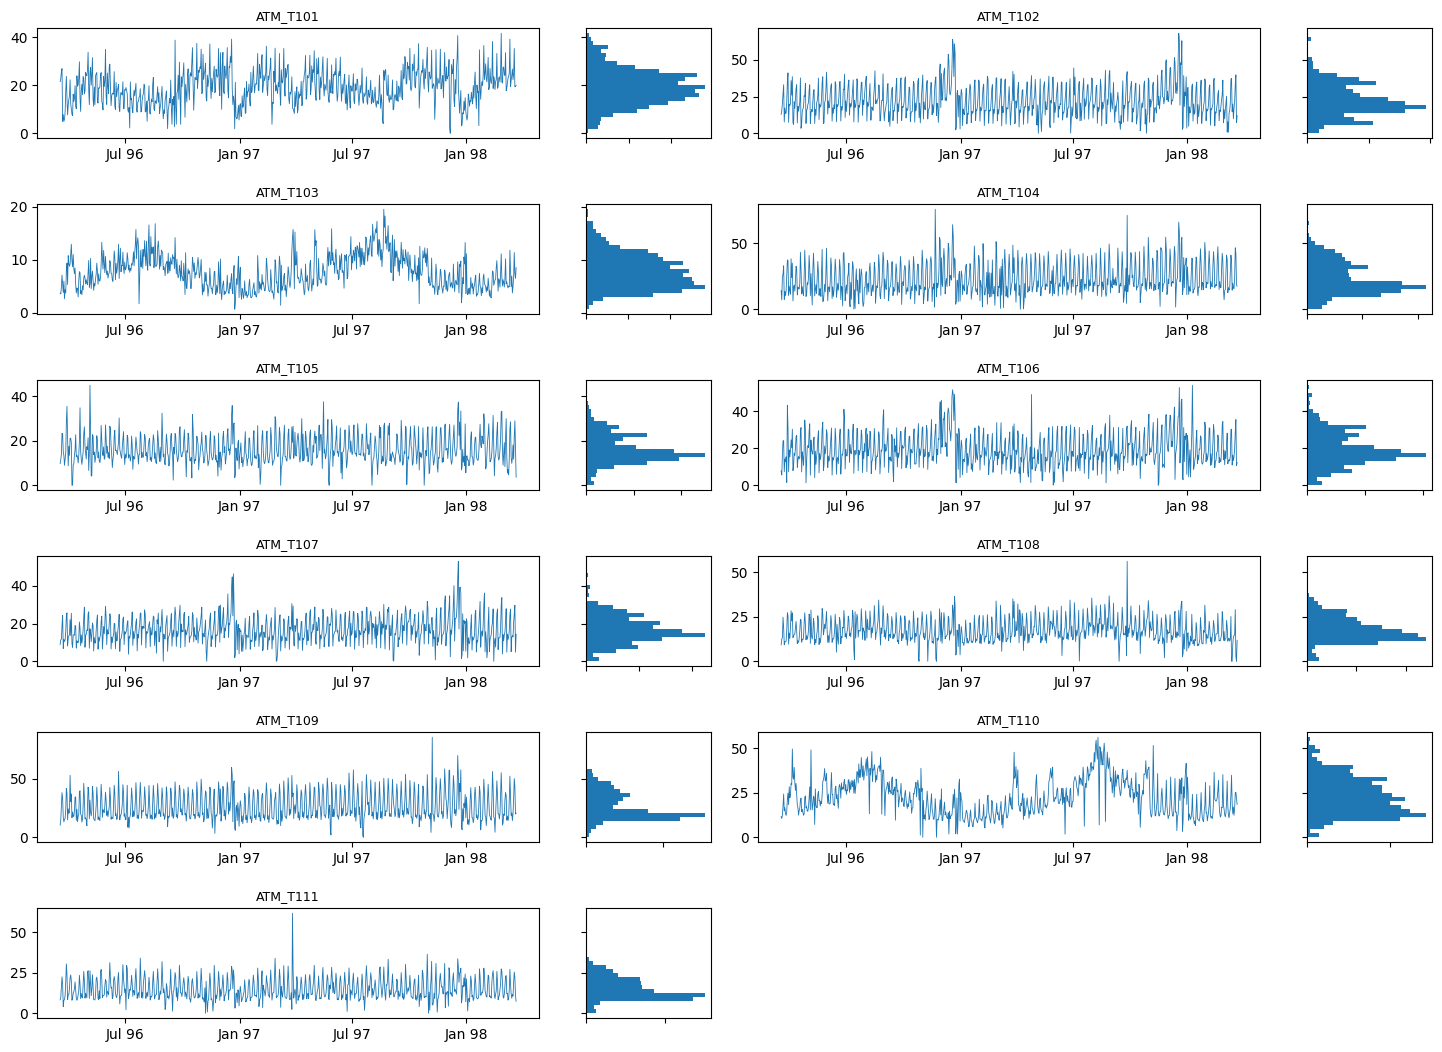

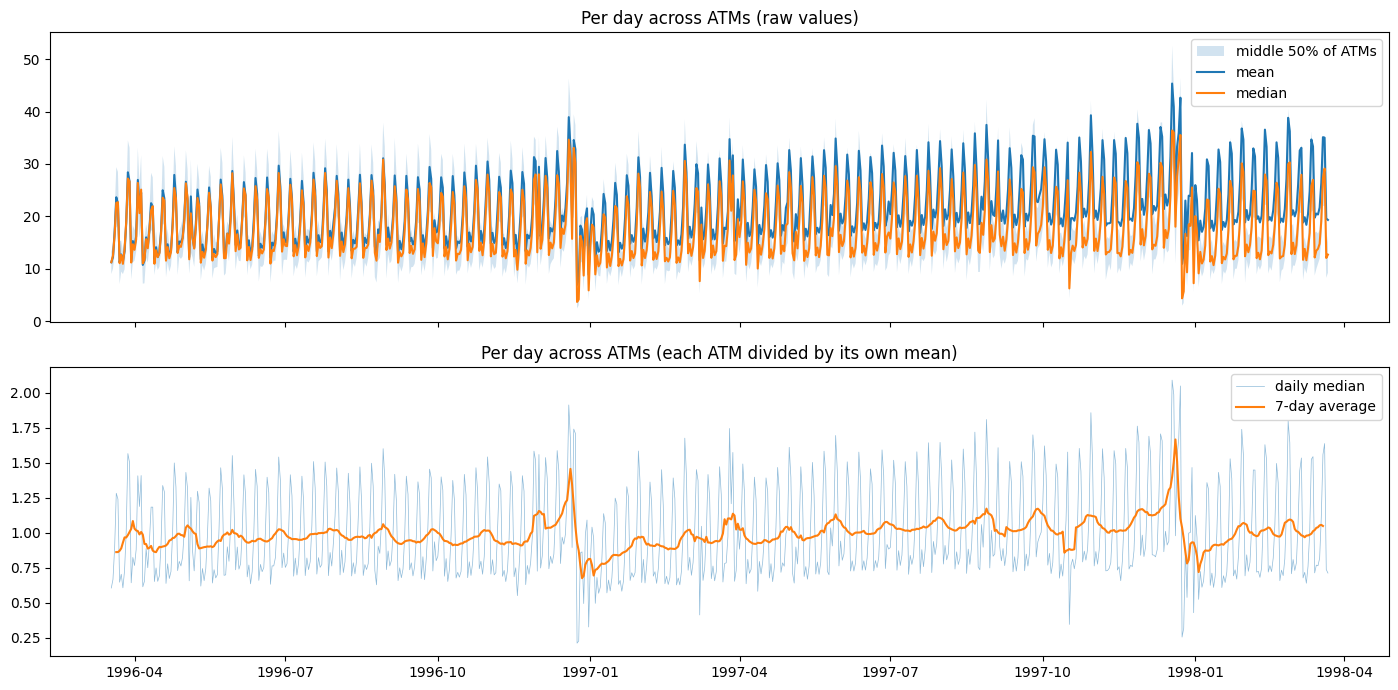

In [3]:
for k in range(0, len(atms), 20):
    chunk = atms[k:k + 20]
    fig = plt.figure(figsize=(18, 22))
    gs = fig.add_gridspec(10, 4, width_ratios=[4, 1, 4, 1], wspace=0.15, hspace=0.6)
    for j, c in enumerate(chunk):
        r, p = divmod(j, 2)
        ax = fig.add_subplot(gs[r, 2 * p]); axh = fig.add_subplot(gs[r, 2 * p + 1], sharey=ax)
        ax.plot(dataframe[c], lw=0.6); ax.set_title(c, fontsize=9)
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
        axh.hist(dataframe[c].dropna(), bins=25, orientation="horizontal")
        axh.tick_params(labelleft=False, labelbottom=False)
    fig.savefig(f"atm_lines_dist_{k // 20 + 1}.png", dpi=110, bbox_inches="tight"); plt.show()
    
norm = dataframe / dataframe.mean()                         
q = dataframe.quantile([.25, .5, .75], axis=1).T
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ax[0].fill_between(q.index, q[.25], q[.75], alpha=0.2, label="middle 50% of ATMs")
ax[0].plot(dataframe.mean(axis=1), label="mean"); ax[0].plot(q[.5], label="median")
ax[0].set_title("Per day across ATMs (raw values)"); ax[0].legend()
med = norm.median(axis=1)
ax[1].plot(med, lw=0.5, alpha=0.5, label="daily median")
ax[1].plot(med.rolling(7, center=True).mean(), label="7-day average")
ax[1].set_title("Per day across ATMs (each ATM divided by its own mean)"); ax[1].legend()
fig.tight_layout(); fig.savefig("daily_mean_median.png", dpi=120); plt.show()

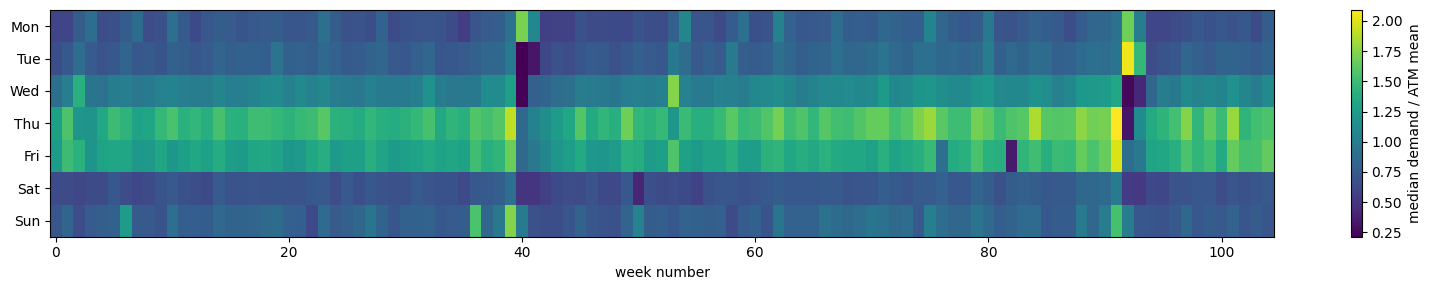

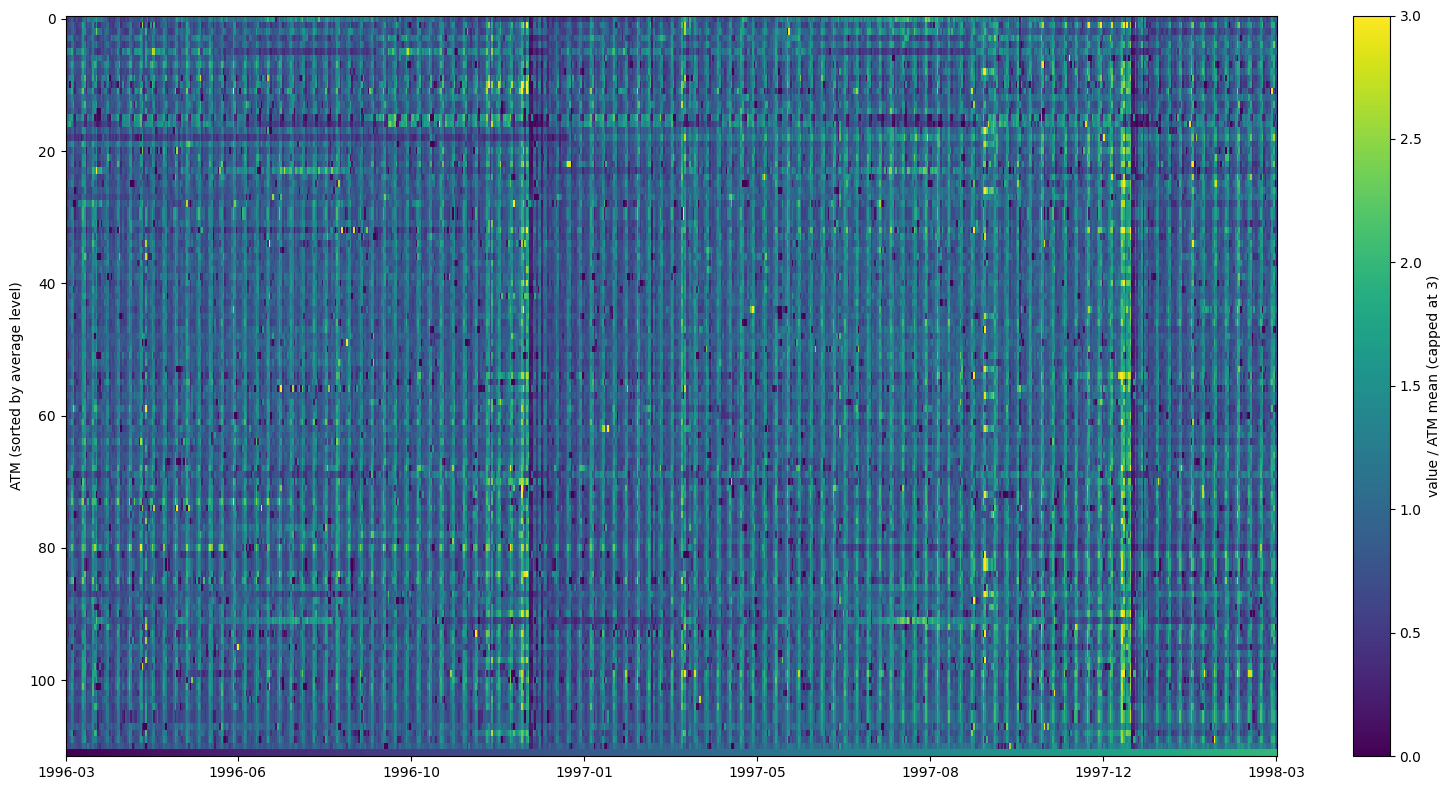

In [4]:
cal = pd.DataFrame({"v": med, "dow": med.index.dayofweek,
                    "wk": ((med.index - med.index[0]).days + med.index[0].dayofweek) // 7}
                   ).pivot(index="dow", columns="wk", values="v")
fig, ax = plt.subplots(figsize=(16, 3))
im = ax.imshow(cal, aspect="auto", cmap="viridis")
ax.set_yticks(range(7)); ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xlabel("week number"); fig.colorbar(im, ax=ax, label="median demand / ATM mean")
fig.tight_layout(); fig.savefig("heatmap_weekday_week.png", dpi=120); plt.show()

order = dataframe.mean().sort_values().index
cmap = plt.get_cmap("viridis").copy(); cmap.set_bad("red")
fig, ax = plt.subplots(figsize=(16, 8))
im = ax.imshow(norm[order].T.values, aspect="auto", cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
t = np.linspace(0, len(dataframe) - 1, 8).astype(int)
ax.set_xticks(t); ax.set_xticklabels([dataframe.index[i].strftime("%Y-%m") for i in t])
ax.set_ylabel("ATM (sorted by average level)")
fig.colorbar(im, ax=ax, label="value / ATM mean (capped at 3)")
fig.tight_layout(); fig.savefig("heatmap_atm_day.png", dpi=120); plt.show()